# When is fine-tuning worth it? Text-to-SQL with Llama 3.2 3B (LoRA vs QLoRA)

**Runtime:** Colab, T4 GPU (Runtime > Change runtime type). You also need access to `meta-llama/Llama-3.2-3B-Instruct` on Hugging Face (request it on the model page) and an HF token.

**How to run:** top to bottom. Every step ends with a **Check** cell that asserts something. If a check fails, stop and fix it before moving on. All results are saved to Google Drive, and every training run is cached, so if Colab disconnects you can re-run the notebook and it skips finished runs.

| Part | What it does |
|---|---|
| 0 | Utilities: synthetic SQLite databases, execution-based scoring, stats helpers |
| 1 | Data audit, clean splits (no schema or near-duplicate leakage), out-of-distribution set |
| 2 | Evaluation harness (prompting, generation, scoring) |
| 3 | Baselines: zero-shot, few-shot, few-shot + better prompt |
| 4 | LoRA vs QLoRA (3 seeds) and ablations (rank, target modules) |
| 5 | Learning curve, confidence intervals, McNemar tests, OOD, forgetting, error analysis |

**v2 changes:** double-quoted SQL literals are now seeded into the synthetic databases (v1 wrongly dropped about 60% of candidates as "empty"), the OOD set has 60 questions, peak memory is measured cleanly, and training cells **re-score adapters already saved on your Drive** instead of retraining them when the data version changes.


**Step 1 (run once):** install packages, then **Runtime > Restart session** and continue from the next cell. Do NOT re-run the install cell after restarting. Skipping the restart causes `pyarrow ... binary incompatibility` errors.

In [1]:
!pip install -q -U transformers peft bitsandbytes datasets accelerate scipy scikit-learn pyarrow
!pip uninstall -y -q torchao      # Colab's old torchao breaks peft's LoRA import
# >>> now: Runtime > Restart session, then run the cells below (not this one) <<<

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.4/62.4 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 119.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 58.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 19.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 51.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 67.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 108.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 11.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.


In [2]:
from huggingface_hub import login
login()   # paste your HF token (needs access to the Llama 3.2 repo)

In [4]:
import os, re, json, gc, time, random, sqlite3, hashlib, warnings
from pathlib import Path
import numpy as np
import pandas as pd
warnings.filterwarnings("ignore")

# ---------------- config (change here, nowhere else) ----------------
SEED         = 42
MODEL_ID     = "meta-llama/Llama-3.2-3B-Instruct"
N_TRAIN_POOL = 5000     # max training examples (learning curve uses prefixes of this)
N_VAL, N_TEST = 500, 500
N_MAIN       = 2000     # training size for the main LoRA vs QLoRA comparison
N_ABL        = 1000     # training size for ablations (kept small to fit Colab time)
SIM_THRESH   = 0.90     # TF-IDF cosine above this = near-duplicate of a training example
MAX_LEN      = 384      # max tokens per training example
SEEDS        = [0, 1, 2]
DATA_VERSION = "v2"     # results saved with another version are re-scored (adapters reused) instead of trusted
REPORT_TO    = "none"   # set to "wandb" if you want Weights & Biases logging

try:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT = Path("/content/drive/MyDrive/sql_finetune")
except ImportError:
    OUT = Path("./sql_finetune")
for sub in ["results", "preds", "adapters", "ckpt"]:
    (OUT / sub).mkdir(parents=True, exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
print("outputs ->", OUT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
outputs -> /content/drive/MyDrive/sql_finetune


## Part 0: Utilities

The dataset has schemas and gold SQL but **no table rows**, so to measure *execution accuracy* we build a small SQLite database for every example with random rows. One trap: if the random data never contains the literals used in the question (e.g. `'sales'`), both gold and predicted queries return nothing and look "equal". So the generator **seeds each column with the literals found in the gold query** (and values just above/below numeric thresholds), and we later drop examples where the gold query still returns an empty result.

In [5]:
NUM_TYPES = ("INT", "REAL", "FLOA", "DOUB", "NUM", "DEC")
WORDS = ["alpha", "beta", "gamma", "delta", "omega", "north", "south", "east",
         "west", "red", "blue", "green", "smith", "jones", "lee", "kim"]

def norm_sql(s):
    s = re.sub(r"\s+", " ", (s or "").strip().rstrip(";").strip()).lower()
    s = re.sub(r"\s*([(),=<>!+\-*/])\s*", r"\1", s)
    return s.replace('"', "'")

def get_literals(sql):
    # sql-create-context writes most string literals in DOUBLE quotes (WHERE name = "Beirut"), SQLite accepts both
    no_str = re.sub(r"'[^']*'|\"[^\"]*\"", " ", sql)
    strs = re.findall(r"'([^']*)'", sql) + re.findall(r'"([^"]*)"', sql)
    nums = [float(x) for x in re.findall(r"(?<![\w.])\d+(?:\.\d+)?(?![\w.])", no_str)]
    return strs, nums

def _rand_value(ctype, strs, nums, rng):
    if rng.random() < 0.03:
        return None
    if any(k in (ctype or "").upper() for k in NUM_TYPES):
        pool = [rng.randint(0, 100) for _ in range(6)]
        for x in nums:
            pool += [x, x, x + 1, x - 1, x * 0.5, x * 1.5]
        v = rng.choice(pool)
        return int(v) if float(v).is_integer() else v
    pool = list(WORDS) + strs * 6 + [str(int(x)) for x in nums] * 2
    return rng.choice(pool)

def make_db(context, gold_sql=None, n_rows=60, seed=None):
    # Returns an in-memory sqlite connection with random rows, or None if the schema is not valid SQLite.
    if seed is None:
        seed = int(hashlib.md5(((context or "") + (gold_sql or "")).encode()).hexdigest()[:8], 16)
    rng = random.Random(seed)
    con = sqlite3.connect(":memory:")
    try:
        con.executescript(context)
    except Exception:
        con.close()
        return None
    strs, nums = get_literals(gold_sql or "")
    strs = [s.strip("%") for s in strs if s.strip("%")]
    tables = [r[0] for r in con.execute(
        "SELECT name FROM sqlite_master WHERE type='table' AND name NOT LIKE 'sqlite_%'")]
    if not tables:
        con.close()
        return None
    for t in tables:
        cols = con.execute(f'PRAGMA table_info("{t}")').fetchall()
        q = f'INSERT OR IGNORE INTO "{t}" VALUES ({",".join("?" * len(cols))})'
        for _ in range(n_rows):
            try:
                con.execute(q, [_rand_value(c[2], strs, nums, rng) for c in cols])
            except sqlite3.Error:
                pass
    con.commit()
    return con

def run_sql(con, sql, max_rows=1000):
    # Executes ONE read-only query with a time limit. Returns (ok, rows, error_message).
    if not re.match(r"^\s*(select|with)\b", sql or "", re.I):
        return False, None, "not a select statement"
    state = {"n": 0}
    def handler():
        state["n"] += 1
        return 1 if state["n"] > 200 else 0      # ~2M VM steps, then abort
    con.set_progress_handler(handler, 10000)
    try:
        cur = con.execute(sql)
        return True, cur.fetchmany(max_rows), None
    except Exception as e:
        return False, None, str(e)
    finally:
        con.set_progress_handler(None, 0)

def _cell(v):
    if v is None: return "null"
    if isinstance(v, (int, float)): return repr(round(float(v), 4))
    return repr(str(v))

def canon(rows, ordered):
    # Row = sorted cells, so column order does not matter. Row order matters only if gold has ORDER BY.
    out = [tuple(sorted(_cell(v) for v in r)) for r in rows]
    return out if ordered else sorted(out)

def exec_eval(context, gold, pred, fixed_script=None):
    out = dict(valid=False, exec_ok=False, gold_ok=False, gold_nonempty=False, err=None)
    if fixed_script:
        con = sqlite3.connect(":memory:"); con.executescript(fixed_script)
    else:
        con = make_db(context, gold)
    if con is None:
        out["err"] = "bad_schema"; return out
    ok_g, rows_g, err_g = run_sql(con, gold)
    out["gold_ok"] = ok_g
    if not ok_g:
        out["err"] = "gold_error: " + str(err_g); con.close(); return out
    out["gold_nonempty"] = len(rows_g) > 0
    ok_p, rows_p, err_p = run_sql(con, pred)
    out["valid"], out["err"] = ok_p, err_p
    if ok_p:
        ordered = " order by " in " " + gold.lower() + " "
        out["exec_ok"] = canon(rows_g, ordered) == canon(rows_p, ordered)
    con.close()
    return out

def extract_sql(text):
    # Pull the SQL out of a model reply (handles ```sql fences, chatty prefixes, trailing explanations).
    t = (text or "").strip()
    m = re.search(r"```(?:sqlite|sql)?\s*(.*?)```", t, re.S | re.I)
    if m:
        t = m.group(1).strip()
    else:
        t = re.sub(r"^```(?:sqlite|sql)?", "", t, flags=re.I).strip()
        m = re.search(r"^\s*(select|with)\b", t, re.I | re.M) or re.search(r"\bselect\b", t, re.I)
        if m:
            t = t[m.start():]
    t = re.split(r"\n\s*\n", t)[0]
    return t.split(";")[0].strip()

AGG = re.compile(r"\b(count|sum|avg|min|max)\s*\(")
def categorize(gold, pred, valid, exec_ok, err):
    if exec_ok: return "correct"
    if not (pred or "").strip(): return "empty output"
    if not valid:
        e = (err or "").lower()
        if "not a select" in e: return "syntax error"          # output was not SQL at all (prose, garbage, non-SELECT)
        if "no such table" in e: return "hallucinated table"
        if "no such column" in e: return "hallucinated column"
        if "syntax error" in e or "incomplete input" in e: return "syntax error"
        return "other execution error"
    g, p = gold.lower(), pred.lower()
    if sorted(AGG.findall(g)) != sorted(AGG.findall(p)): return "wrong aggregation"
    if len(re.findall(r"\bjoin\b", g)) != len(re.findall(r"\bjoin\b", p)): return "join mismatch"
    if ("order by" in g) != ("order by" in p) or ("limit" in g) != ("limit" in p): return "ordering/limit"
    gs, gn = get_literals(g); ps, pn = get_literals(p)
    if set(gs) != set(ps) or set(gn) != set(pn): return "wrong literal/value"
    return "wrong columns/logic"

def score_preds(df, preds, fixed_script=None):
    rows = []
    for ctx, gold, pred in zip(df["context"], df["answer"], preds):
        r = exec_eval(ctx, gold, pred, fixed_script)
        r["exact"] = norm_sql(pred) == norm_sql(gold)
        r["pred"] = pred
        r["category"] = categorize(gold, pred, r["valid"], r["exec_ok"], r["err"])
        rows.append(r)
    return pd.concat([df.reset_index(drop=True), pd.DataFrame(rows)], axis=1)

def summarize(res):
    ne = res[res.gold_nonempty]
    return dict(n=int(len(res)), exact=float(res.exact.mean()), valid=float(res.valid.mean()),
                exec_acc=float(res.exec_ok.mean()),
                exec_acc_nonempty=float(ne.exec_ok.mean()) if len(ne) else float("nan"),
                n_nonempty=int(len(ne)))

# ---- statistics ----
from scipy.stats import binomtest
def bootstrap_ci(x, n_boot=2000, seed=0, alpha=0.05):
    x = np.asarray(x, float)
    idx = np.random.default_rng(seed).integers(0, len(x), (n_boot, len(x)))
    return tuple(np.percentile(x[idx].mean(1), [100 * alpha / 2, 100 * (1 - alpha / 2)]))

def mcnemar_exact(a, b):
    # a, b: boolean "was correct" arrays on the SAME examples. Returns (p_value, only_b_right, only_a_right)
    a, b = np.asarray(a, bool), np.asarray(b, bool)
    n01, n10 = int((~a & b).sum()), int((a & ~b).sum())
    p = 1.0 if n01 + n10 == 0 else binomtest(n01, n01 + n10, 0.5).pvalue
    return p, n01, n10

In [6]:
# ---------- CHECK 0: unit tests for the utilities ----------
ctx = "CREATE TABLE emp (id INTEGER, name TEXT, salary INTEGER, dept TEXT)"
gold = "SELECT name FROM emp WHERE salary > 50000 AND dept = 'sales'"

r = exec_eval(ctx, gold, gold)
assert r["gold_ok"] and r["gold_nonempty"] and r["exec_ok"], r                   # gold == gold
assert not exec_eval(ctx, gold, "SELECT name FROM emp WHERE dept = 'sales'")["exec_ok"]   # missing filter is caught
r = exec_eval(ctx, gold, "SELECT nme FROM emp")
assert not r["valid"] and categorize(gold, "SELECT nme FROM emp", r["valid"], r["exec_ok"], r["err"]) == "hallucinated column"
r = exec_eval(ctx, gold, "SELEC name FROM emp")
assert categorize(gold, "SELEC name FROM emp", r["valid"], r["exec_ok"], r["err"]) == "syntax error", r
assert not exec_eval(ctx, gold, "DROP TABLE emp")["valid"]                      # writes are blocked
assert exec_eval(ctx, "SELECT name, dept FROM emp", "SELECT dept, name FROM emp")["exec_ok"]  # column order ignored
dq = 'SELECT name FROM emp WHERE dept = "Marketing"'
assert exec_eval(ctx, dq, dq)["gold_nonempty"], "double-quoted literals must be seeded into the synthetic data"
assert make_db("this is not sql") is None

assert extract_sql("```sql\nSELECT a FROM t;\n```\nThis query...") == "SELECT a FROM t"
assert extract_sql("Here is the query:\nSELECT a FROM t WHERE b = 1\n\nIt selects a.") == "SELECT a FROM t WHERE b = 1"
assert extract_sql("SELECT a FROM t; SELECT b FROM t") == "SELECT a FROM t"
assert norm_sql("SELECT  a ,b FROM t ;") == norm_sql("select a, b from t")

a = np.array([1, 1, 0, 0, 1, 1, 0, 1] * 25, bool); b = np.array([1, 1, 1, 1, 1, 1, 1, 1] * 25, bool)
lo, hi = bootstrap_ci(a)
assert lo < a.mean() < hi
p, n01, n10 = mcnemar_exact(a, b); assert p < 0.05 and n10 == 0 and n01 > 0
print("Check 0 passed: SQL harness and stats helpers behave as expected")

Check 0 passed: SQL harness and stats helpers behave as expected


## Part 1: Data audit, clean splits, out-of-distribution set

What we check and why:
1. **Exact duplicates** and **conflicting labels** (same question + schema, different SQL) in the raw data.
2. **Gold SQL that does not run** on its own schema (noisy labels).
3. **Gold SQL that returns nothing** on the synthetic data (would inflate execution accuracy), dropped from val/test.
4. **Schema leakage**: val/test examples whose exact `CREATE TABLE` appears in training are removed, so the test measures *unseen schemas*.
5. **Near-duplicates**: val/test questions too similar to a training question (TF-IDF cosine above `SIM_THRESH`) are removed.

In [7]:
from datasets import load_dataset
raw = load_dataset("b-mc2/sql-create-context", split="train").to_pandas()[["question", "context", "answer"]]
print(len(raw), "raw rows")
raw.head(3)

78577 raw rows


,question,context,answer
0,How many heads of the departments are older th...,CREATE TABLE head (age INTEGER),SELECT COUNT(*) FROM head WHERE age > 56
1,"List the name, born state and age of the heads...","CREATE TABLE head (name VARCHAR, born_state VA...","SELECT name, born_state, age FROM head ORDER B..."
2,"List the creation year, name and budget of eac...","CREATE TABLE department (creation VARCHAR, nam...","SELECT creation, name, budget_in_billions FROM..."


In [8]:
audit = {"raw_rows": len(raw)}
df = raw.copy()
for c in ["question", "context", "answer"]:
    df[c] = df[c].astype(str).str.strip()
df["ans_norm"] = df["answer"].map(norm_sql)

audit["exact_duplicates"] = int(df.duplicated(["question", "context", "answer"]).sum())
df = df.drop_duplicates(["question", "context", "ans_norm"])           # also catches duplicates that differ only in whitespace/case

key = df["question"] + "||" + df["context"]
n_unique_answers = df.groupby(key)["ans_norm"].transform("nunique")
audit["rows_with_conflicting_labels"] = int((n_unique_answers > 1).sum())
df = df[n_unique_answers == 1].reset_index(drop=True)
audit["after_dedupe_and_conflicts"] = len(df)
print(pd.Series(audit))

raw_rows                        78577
exact_duplicates                    0
rows_with_conflicting_labels        2
after_dedupe_and_conflicts      78575
dtype: int64


In [9]:
# Sample a candidate pool, then validate every gold query on its synthetic database.
n_cand_eval = 1200                                                       # oversample val/test because filters will remove some
cand = df.sample(n=N_TRAIN_POOL + 2 * n_cand_eval, random_state=SEED).reset_index(drop=True)

def check_gold(ctx, gold):
    con = make_db(ctx, gold)
    if con is None: return "bad_schema"
    ok, rows, _ = run_sql(con, gold); con.close()
    return "gold_error" if not ok else ("ok" if rows else "gold_empty")

t0 = time.time()
cand["gold_status"] = [check_gold(c, g) for c, g in zip(cand.context, cand.answer)]
print(f"{time.time() - t0:.0f}s")
print(cand.gold_status.value_counts())
audit.update({f"candidates_{k}": int(v) for k, v in cand.gold_status.value_counts().items()})

5s
gold_status
ok            6728
gold_empty     524
gold_error     123
bad_schema      25
Name: count, dtype: int64


In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer

def max_sim(train_text, other_text):
    vec = TfidfVectorizer(ngram_range=(1, 2)).fit(pd.concat([train_text, other_text]))
    sims = vec.transform(other_text) @ vec.transform(train_text).T
    return sims.max(axis=1).toarray().ravel()

train_c = cand.iloc[:N_TRAIN_POOL]
val_c   = cand.iloc[N_TRAIN_POOL: N_TRAIN_POOL + n_cand_eval]
test_c  = cand.iloc[N_TRAIN_POOL + n_cand_eval:]

# training: drop only broken labels (empty gold results are still valid labels)
train = train_c[train_c.gold_status.isin(["ok", "gold_empty"])].sample(frac=1, random_state=SEED).reset_index(drop=True)
audit["train_dropped_bad_gold"] = len(train_c) - len(train)
train_schemas = set(train.context)
train_text = train.question + " " + train.answer

def clean_eval(split_c, name):
    s = split_c[split_c.gold_status == "ok"]; n_ok = len(s)
    s = s[~s.context.isin(train_schemas)]; n_schema = len(s)
    sim = max_sim(train_text, s.question + " " + s.answer)
    s = s[sim < SIM_THRESH]
    audit[f"{name}_candidates"] = len(split_c)
    audit[f"{name}_after_gold_ok_and_nonempty"] = n_ok
    audit[f"{name}_after_schema_disjoint"] = n_schema
    audit[f"{name}_after_near_dup_filter"] = len(s)
    return s.reset_index(drop=True)

val_all, test_all = clean_eval(val_c, "val"), clean_eval(test_c, "test")
val, test = val_all.head(N_VAL).copy(), test_all.head(N_TEST).copy()
print(pd.Series(audit).to_string())
print(f"\nFINAL sizes  train={len(train)}  val={len(val)}  test={len(test)}")

raw_rows                           78577
exact_duplicates                       0
rows_with_conflicting_labels           2
after_dedupe_and_conflicts         78575
candidates_ok                       6728
candidates_gold_empty                524
candidates_gold_error                123
candidates_bad_schema                 25
train_dropped_bad_gold               103
val_candidates                      1200
val_after_gold_ok_and_nonempty      1104
val_after_schema_disjoint           1080
val_after_near_dup_filter           1080
test_candidates                     1200
test_after_gold_ok_and_nonempty     1101
test_after_schema_disjoint          1090
test_after_near_dup_filter          1089

FINAL sizes  train=4897  val=500  test=500


In [11]:
# ---------- CHECK 1: the splits are what we claim ----------
assert len(val) >= 300 and len(test) >= 300, "too many examples were filtered out; raise n_cand_eval or lower SIM_THRESH strictness"
assert (val.gold_status == "ok").all() and (test.gold_status == "ok").all()
assert not (set(val.context) & train_schemas) and not (set(test.context) & train_schemas), "schema leakage"
q = lambda d: set(zip(d.question, d.context))
assert not (q(train) & q(val)) and not (q(train) & q(test)) and not (q(val) & q(test)), "duplicate examples across splits"
assert max_sim(train_text, test.question + " " + test.answer).max() < SIM_THRESH
N_LIST = [n for n in [250, 500, 1000, 2000, 5000] if n <= len(train)]
assert N_MAIN <= len(train) and N_ABL <= len(train)

for name, d in [("train", train), ("val", val), ("test", test)]:
    d.drop(columns=["ans_norm"], errors="ignore").to_json(OUT / f"{name}.jsonl", orient="records", lines=True)
json.dump(audit, open(OUT / "audit.json", "w"), indent=1)
print("Check 1 passed. Learning-curve sizes:", N_LIST)

Check 1 passed. Learning-curve sizes: [250, 500, 1000, 2000]


In [12]:
# ---------- Out-of-distribution set: a realistic 4-table shop database with hand-written questions ----------
# The training data is mostly single-table. This set needs multi-table JOINs, GROUP BY/HAVING, subqueries, etc.
SHOP_SCHEMA = """CREATE TABLE customers (customer_id INTEGER PRIMARY KEY, name TEXT, country TEXT, signup_year INTEGER);
CREATE TABLE products (product_id INTEGER PRIMARY KEY, product_name TEXT, category TEXT, price REAL);
CREATE TABLE orders (order_id INTEGER PRIMARY KEY, customer_id INTEGER, order_date TEXT, status TEXT);
CREATE TABLE order_items (order_id INTEGER, product_id INTEGER, quantity INTEGER);"""

def _shop_data():
    rng = random.Random(0)
    cust = [(1,'Asha','India',2019),(2,'Ben','USA',2020),(3,'Chen','China',2018),(4,'Diya','India',2021),
            (5,'Emma','UK',2019),(6,'Farid','UAE',2022),(7,'Grace','USA',2021),(8,'Hiro','Japan',2020)]
    prod = [(1,'Laptop','electronics',900.0),(2,'Phone','electronics',600.0),(3,'Desk','furniture',250.0),
            (4,'Chair','furniture',120.0),(5,'Notebook','stationery',3.5),(6,'Pen','stationery',1.2),
            (7,'Monitor','electronics',300.0),(8,'Lamp','furniture',45.0)]
    statuses = ["shipped", "pending", "cancelled"]
    orders, items = [], []
    for oid in range(1, 25):
        cid = oid if oid <= 7 else rng.randint(1, 7)         # customer 8 never orders
        orders.append((oid, cid, f"2023-{rng.randint(1, 12):02d}-{rng.randint(1, 28):02d}", statuses[oid % 3]))
        for pid in rng.sample(range(1, 8), rng.randint(1, 3)):  # product 8 never ordered
            items.append((oid, pid, rng.randint(1, 5)))
    lines = []
    for tname, rows in [("customers", cust), ("products", prod), ("orders", orders), ("order_items", items)]:
        for r in rows:
            lines.append(f"INSERT INTO {tname} VALUES ({', '.join(repr(v) for v in r)});")
    return "\n".join(lines)

SHOP_SCRIPT = SHOP_SCHEMA + "\n" + _shop_data()

OOD_QA = [
 ("How many customers are there?", "SELECT COUNT(*) FROM customers"),
 ("List the names of customers from India.", "SELECT name FROM customers WHERE country = 'India'"),
 ("What is the average price of products in the electronics category?", "SELECT AVG(price) FROM products WHERE category = 'electronics'"),
 ("Which product has the highest price?", "SELECT product_name FROM products ORDER BY price DESC LIMIT 1"),
 ("How many orders were shipped?", "SELECT COUNT(*) FROM orders WHERE status = 'shipped'"),
 ("List the names of customers who signed up after 2019.", "SELECT name FROM customers WHERE signup_year > 2019"),
 ("How many products are in each category?", "SELECT category, COUNT(*) FROM products GROUP BY category"),
 ("Show each customer name with the status of their orders.", "SELECT c.name, o.status FROM customers c JOIN orders o ON c.customer_id = o.customer_id"),
 ("How many orders has each customer placed? Show the customer name and the count.", "SELECT c.name, COUNT(*) FROM customers c JOIN orders o ON c.customer_id = o.customer_id GROUP BY c.customer_id"),
 ("Which customers have placed more than 2 orders?", "SELECT c.name FROM customers c JOIN orders o ON c.customer_id = o.customer_id GROUP BY c.customer_id HAVING COUNT(*) > 2"),
 ("What is the total quantity of Laptop ordered?", "SELECT SUM(oi.quantity) FROM order_items oi JOIN products p ON oi.product_id = p.product_id WHERE p.product_name = 'Laptop'"),
 ("List the products that have never been ordered.", "SELECT product_name FROM products WHERE product_id NOT IN (SELECT product_id FROM order_items)"),
 ("What is the total revenue of each order?", "SELECT oi.order_id, SUM(oi.quantity * p.price) FROM order_items oi JOIN products p ON oi.product_id = p.product_id GROUP BY oi.order_id"),
 ("What is the most expensive product in the furniture category?", "SELECT product_name FROM products WHERE category = 'furniture' ORDER BY price DESC LIMIT 1"),
 ("Count customers per country, sorted by count descending and then by country.", "SELECT country, COUNT(*) FROM customers GROUP BY country ORDER BY COUNT(*) DESC, country"),
 ("List the distinct names of customers who ordered a Phone.", "SELECT DISTINCT c.name FROM customers c JOIN orders o ON c.customer_id = o.customer_id JOIN order_items oi ON o.order_id = oi.order_id JOIN products p ON oi.product_id = p.product_id WHERE p.product_name = 'Phone'"),
 ("How many distinct products were ordered?", "SELECT COUNT(DISTINCT product_id) FROM order_items"),
 ("Which products cost more than the average product price?", "SELECT product_name FROM products WHERE price > (SELECT AVG(price) FROM products)"),
 ("What is the total quantity of items in cancelled orders?", "SELECT SUM(oi.quantity) FROM order_items oi JOIN orders o ON oi.order_id = o.order_id WHERE o.status = 'cancelled'"),
 ("List the names of customers from the USA or the UK.", "SELECT name FROM customers WHERE country IN ('USA', 'UK')"),
 ("How many orders were placed after 2023-06-30?", "SELECT COUNT(*) FROM orders WHERE order_date > '2023-06-30'"),
 ("What is the cheapest price in each product category?", "SELECT category, MIN(price) FROM products GROUP BY category"),
 ("List the names of customers whose name starts with the letter A.", "SELECT name FROM customers WHERE name LIKE 'A%'"),
 ("What is the largest quantity in a single order line?", "SELECT MAX(quantity) FROM order_items"),
 ("Show product names and categories ordered by price from lowest to highest.", "SELECT product_name, category FROM products ORDER BY price ASC"),
 ("Which other customers signed up in the same year as Asha?", "SELECT name FROM customers WHERE signup_year = (SELECT signup_year FROM customers WHERE name = 'Asha') AND name <> 'Asha'"),
 ("How many orders are there for each status?", "SELECT status, COUNT(*) FROM orders GROUP BY status"),
 ("Which order ids contain more than one distinct product?", "SELECT order_id FROM order_items GROUP BY order_id HAVING COUNT(DISTINCT product_id) > 1"),
 ("Which customers have not placed any orders?", "SELECT name FROM customers WHERE customer_id NOT IN (SELECT customer_id FROM orders)"),
 ("How many products are there?", "SELECT COUNT(*) FROM products"),
 ("List all distinct countries of our customers.", "SELECT DISTINCT country FROM customers"),
 ("What is the average signup year of customers?", "SELECT AVG(signup_year) FROM customers"),
 ("Which customers are from Japan?", "SELECT name FROM customers WHERE country = 'Japan'"),
 ("What is the price of the Desk?", "SELECT price FROM products WHERE product_name = 'Desk'"),
 ("List the products that cost less than 100.", "SELECT product_name FROM products WHERE price < 100"),
 ("How many orders are pending?", "SELECT COUNT(*) FROM orders WHERE status = 'pending'"),
 ("Show the order ids placed by Asha.", "SELECT o.order_id FROM orders o JOIN customers c ON o.customer_id = c.customer_id WHERE c.name = 'Asha'"),
 ("How many distinct customers have placed orders?", "SELECT COUNT(DISTINCT customer_id) FROM orders"),
 ("What is the total quantity of all ordered items?", "SELECT SUM(quantity) FROM order_items"),
 ("Which product category has the fewest products?", "SELECT category FROM products GROUP BY category ORDER BY COUNT(*) ASC LIMIT 1"),
 ("What is the earliest order date?", "SELECT MIN(order_date) FROM orders"),
 ("List the names of customers who signed up in 2021 or later.", "SELECT name FROM customers WHERE signup_year >= 2021"),
 ("Show the product names and quantities in order 1.", "SELECT p.product_name, oi.quantity FROM order_items oi JOIN products p ON oi.product_id = p.product_id WHERE oi.order_id = 1"),
 ("How many order lines does each order have? Show the order id and the count.", "SELECT order_id, COUNT(*) FROM order_items GROUP BY order_id"),
 ("What is the total revenue across all orders?", "SELECT SUM(oi.quantity * p.price) FROM order_items oi JOIN products p ON oi.product_id = p.product_id"),
 ("Which customers ordered a Laptop?", "SELECT DISTINCT c.name FROM customers c JOIN orders o ON c.customer_id = o.customer_id JOIN order_items oi ON o.order_id = oi.order_id JOIN products p ON oi.product_id = p.product_id WHERE p.product_name = 'Laptop'"),
 ("What is the average quantity per order line?", "SELECT AVG(quantity) FROM order_items"),
 ("List the customers sorted by signup year (oldest first), then by name.", "SELECT name FROM customers ORDER BY signup_year ASC, name ASC"),
 ("How many orders did the customer Chen place?", "SELECT COUNT(*) FROM orders o JOIN customers c ON o.customer_id = c.customer_id WHERE c.name = 'Chen'"),
 ("Which countries have more than one customer?", "SELECT country FROM customers GROUP BY country HAVING COUNT(*) > 1"),
 ("What is the highest price among products in cancelled orders?", "SELECT MAX(p.price) FROM products p JOIN order_items oi ON p.product_id = oi.product_id JOIN orders o ON oi.order_id = o.order_id WHERE o.status = 'cancelled'"),
 ("How many customers signed up before 2020?", "SELECT COUNT(*) FROM customers WHERE signup_year < 2020"),
 ("Which products have a price between 100 and 500?", "SELECT product_name FROM products WHERE price BETWEEN 100 AND 500"),
 ("List the order dates of shipped orders.", "SELECT order_date FROM orders WHERE status = 'shipped'"),
 ("Which order ids have more than 2 order lines?", "SELECT order_id FROM order_items GROUP BY order_id HAVING COUNT(*) > 2"),
 ("What is the name of the customer with the earliest signup year?", "SELECT name FROM customers ORDER BY signup_year ASC LIMIT 1"),
 ("What is the total quantity ordered for each product category?", "SELECT p.category, SUM(oi.quantity) FROM order_items oi JOIN products p ON oi.product_id = p.product_id GROUP BY p.category"),
 ("Which customers have placed a cancelled order?", "SELECT DISTINCT c.name FROM customers c JOIN orders o ON c.customer_id = o.customer_id WHERE o.status = 'cancelled'"),
 ("What is the average price of products that were ordered at least once?", "SELECT AVG(price) FROM products WHERE product_id IN (SELECT product_id FROM order_items)"),
 ("How much has the customer Ben spent in total?", "SELECT SUM(oi.quantity * p.price) FROM customers c JOIN orders o ON c.customer_id = o.customer_id JOIN order_items oi ON o.order_id = oi.order_id JOIN products p ON oi.product_id = p.product_id WHERE c.name = 'Ben'"),
]
ood = pd.DataFrame({"question": [q for q, _ in OOD_QA], "context": SHOP_SCHEMA, "answer": [a for _, a in OOD_QA]})
print(len(ood), "OOD questions")

60 OOD questions


In [13]:
# ---------- CHECK 2: every OOD gold query runs and returns rows ----------
res = score_preds(ood, ood["answer"].tolist(), fixed_script=SHOP_SCRIPT)
assert res.gold_ok.all(), res.loc[~res.gold_ok, ["question", "err"]]
assert res.gold_nonempty.all(), res.loc[~res.gold_nonempty, "question"].tolist()
assert res.exec_ok.all()
print("Check 2 passed: all", len(ood), "OOD gold queries execute and return non-empty results")

Check 2 passed: all 60 OOD gold queries execute and return non-empty results


## Part 2: Evaluation harness

One prompt format is used everywhere (baselines and fine-tuned models), so any difference comes from the model, not the prompt. Metrics: **exact match** (string, normalized), **valid-SQL rate** (does it run?), and **execution accuracy** (same result as the gold query on the database).

In [14]:
SYSTEM_PLUS = ("You are an expert SQLite assistant. Given a schema and a question, reply with exactly one "
               "SQLite query and nothing else. Use only tables and columns that appear in the schema. "
               "No explanations and no markdown.")

def user_msg(ctx, q):
    return f"Schema:\n{ctx}\n\nQuestion: {q}\n\nSQL:"

def build_messages(ctx, q, shots=(), system=None):
    msgs = [{"role": "system", "content": system}] if system else []
    for s in shots:
        msgs += [{"role": "user", "content": user_msg(s["context"], s["question"])},
                 {"role": "assistant", "content": s["answer"]}]
    msgs.append({"role": "user", "content": user_msg(ctx, q)})
    return msgs

EVAL_SETS = {"val":  [("val", val, None)],
             "test": [("test", test, None), ("ood", ood, SHOP_SCRIPT)]}

In [15]:
import torch
from transformers import (AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig, Trainer,
                          TrainingArguments, DataCollatorForSeq2Seq, set_seed)
from peft import LoraConfig, PeftModel, get_peft_model, prepare_model_for_kbit_training
from datasets import Dataset

assert torch.cuda.is_available(), "Switch the runtime to a GPU (T4)."
print(torch.cuda.get_device_name(0))

tok = AutoTokenizer.from_pretrained(MODEL_ID)
if tok.pad_token is None:
    tok.pad_token = tok.eos_token

def load_base(quant):
    kw = dict(torch_dtype=torch.float16, device_map={"": 0})      # fp16: the T4 has no bf16
    if quant:
        kw["quantization_config"] = BitsAndBytesConfig(
            load_in_4bit=True, bnb_4bit_quant_type="nf4",
            bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=torch.float16)
    return AutoModelForCausalLM.from_pretrained(MODEL_ID, **kw)

def rescore_adapter(name, quant, eval_on):
    # Load a SAVED adapter and re-evaluate it (no training). Used when the eval data changed.
    base = load_base(quant)
    model = PeftModel.from_pretrained(base, str(OUT / "adapters" / name))
    metrics = eval_splits(model, name, eval_on)
    del model, base; gc.collect(); torch.cuda.empty_cache()
    return metrics

@torch.no_grad()
def generate_sql(model, prompts, bs=16, max_new=128):
    model.eval()
    tok.padding_side = "left"
    order = np.argsort([len(p) for p in prompts])[::-1]         # long prompts first = fewer OOM surprises
    outs = [None] * len(prompts)
    for i in range(0, len(prompts), bs):
        idx = order[i:i + bs]
        batch = tok([prompts[j] for j in idx], return_tensors="pt", padding=True,
                    add_special_tokens=False).to(model.device)
        gen = model.generate(**batch, max_new_tokens=max_new, do_sample=False, temperature=None,
                             top_p=None, pad_token_id=tok.pad_token_id, use_cache=True)
        texts = tok.batch_decode(gen[:, batch["input_ids"].shape[1]:], skip_special_tokens=True)
        for j, t in zip(idx, texts):
            outs[j] = t
    tok.padding_side = "right"
    return outs

def eval_splits(model, name, which, shots=(), system=None, limit=None):
    out = {}
    for split, d, script in EVAL_SETS[which]:
        d = d.head(limit) if limit else d
        prompts = [tok.apply_chat_template(build_messages(c, q, shots, system), tokenize=False,
                                           add_generation_prompt=True)
                   for c, q in zip(d.context, d.question)]
        raw_out = generate_sql(model, prompts)
        res = score_preds(d, [extract_sql(t) for t in raw_out], script)
        res["raw_output"] = raw_out
        res.drop(columns=["ans_norm"], errors="ignore").to_csv(OUT / "preds" / f"{name}__{split}.csv", index=False)
        out[split] = summarize(res)
    return out

def mmlu_acc(model, n=300, bs=8):
    # Forgetting check: general-knowledge accuracy on n MMLU validation questions (A/B/C/D next-token scoring).
    ds = load_dataset("cais/mmlu", "all", split="validation").shuffle(seed=0).select(range(n))
    letter_ids = [tok.encode(" " + l, add_special_tokens=False)[-1] for l in "ABCD"]
    prompts = [f"{e['question']}\nA. {e['choices'][0]}\nB. {e['choices'][1]}\nC. {e['choices'][2]}\n"
               f"D. {e['choices'][3]}\nAnswer:" for e in ds]
    model.eval(); tok.padding_side = "left"; correct = 0
    with torch.no_grad():
        for i in range(0, n, bs):
            batch = tok(prompts[i:i + bs], return_tensors="pt", padding=True).to(model.device)
            logits = model(**batch).logits[:, -1, :][:, letter_ids]
            correct += int((logits.argmax(-1).cpu().numpy() == np.array(ds["answer"][i:i + bs])).sum())
    tok.padding_side = "right"
    return correct / n

Tesla T4


In [16]:
# ---------- CHECK 3: the harness works end to end (cheap) ----------
# (a) Scoring the gold answers as predictions must give 100%.
for nm, d in [("val", val), ("test", test)]:
    s = summarize(score_preds(d, d["answer"].tolist()))
    assert s["exec_acc"] == 1.0 and s["valid"] == 1.0 and s["exact"] == 1.0, (nm, s)
# (b) A dumb constant prediction must score low (execution accuracy is not trivially satisfiable).
dumb = summarize(score_preds(test, ["SELECT 1"] * len(test)))
assert dumb["exec_acc"] < 0.10, dumb
print("Check 3a passed: gold-as-prediction = 100%, constant 'SELECT 1' =", round(dumb["exec_acc"], 3))

Check 3a passed: gold-as-prediction = 100%, constant 'SELECT 1' = 0.006


In [17]:
# (c) Check the chat template and the training-example encoder (needs the tokenizer, so GPU cell above must have run).
def encode_example(ex):
    prompt = tok.apply_chat_template(build_messages(ex["context"], ex["question"]), tokenize=False,
                                     add_generation_prompt=True)
    p_ids = tok(prompt, add_special_tokens=False)["input_ids"]
    a_ids = tok(ex["answer"].strip() + "<|eot_id|>", add_special_tokens=False)["input_ids"]
    ids, labels = (p_ids + a_ids)[:MAX_LEN], ([-100] * len(p_ids) + a_ids)[:MAX_LEN]
    return {"input_ids": ids, "attention_mask": [1] * len(ids), "labels": labels}

enc = [encode_example(r) for r in train.head(300).to_dict("records")]
lens = np.array([len(e["input_ids"]) for e in enc])
print("token length  mean %.0f  p95 %.0f  max %d" % (lens.mean(), np.percentile(lens, 95), lens.max()))
assert (lens < MAX_LEN).mean() > 0.99, "many examples truncated: raise MAX_LEN"
e = enc[0]
assert e["labels"][-1] == tok.convert_tokens_to_ids("<|eot_id|>"), "answer must end with <|eot_id|>"
assert e["labels"][0] == -100 and any(l != -100 for l in e["labels"])
print("answer tokens trained on:", repr(tok.decode([l for l in e["labels"] if l != -100])))
print("Check 3b passed: only the SQL answer (and end-of-turn) contributes to the loss")

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


token length  mean 96  p95 118  max 162
answer tokens trained on: 'SELECT arabic_capital_name FROM table_15694696_1 WHERE english_capital_name = "Beirut"<|eot_id|>'
Check 3b passed: only the SQL answer (and end-of-turn) contributes to the loss


## Part 3: Baselines (the "before" numbers)

Three prompting setups on the **same untouched base model**: zero-shot, 3-shot, and 5-shot with a stricter system prompt. If a well-prompted base model already does fine, fine-tuning is not needed, and that is a legitimate finding.

In [18]:
shot_pool = train.sample(5, random_state=1).to_dict("records")
BASELINES = {"zero_shot":      dict(shots=(),            system=None),
             "few_shot_3":     dict(shots=shot_pool[:3], system=None),
             "few_shot_plus":  dict(shots=shot_pool,     system=SYSTEM_PLUS)}

base = load_base(quant=False)
for variant, kw in BASELINES.items():
    path = OUT / "results" / f"baseline_{variant}.json"
    if path.exists() and json.load(open(path)).get("data_version") == DATA_VERSION:
        print("cached:", variant); continue
    t0 = time.time()
    metrics = eval_splits(base, f"baseline_{variant}", "test", **kw)
    json.dump({"name": f"baseline_{variant}", "method": "baseline", "variant": variant,
               "metrics": metrics, "data_version": DATA_VERSION}, open(path, "w"), indent=1)
    print(variant, f"{time.time() - t0:.0f}s", {k: round(v["exec_acc"], 3) for k, v in metrics.items()})

path = OUT / "results" / "base_mmlu.json"
if not path.exists():
    json.dump({"mmlu": mmlu_acc(base)}, open(path, "w"))
print("base MMLU subset accuracy:", json.load(open(path))["mmlu"])
del base; gc.collect(); torch.cuda.empty_cache()

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

cached: zero_shot
cached: few_shot_3
cached: few_shot_plus
base MMLU subset accuracy: 0.5833333333333334


In [19]:
# ---------- CHECK 4: baseline outputs look sane ----------
b = pd.read_csv(OUT / "preds" / "baseline_few_shot_plus__test.csv").fillna({"pred": ""})
assert len(b) == len(test)
print("valid-SQL rate:", round(b.valid.mean(), 3), "| empty outputs:", int((b.pred == "").sum()))
for _, r in b.head(3).iterrows():
    print("\nQ   :", r.question, "\nGOLD:", r.answer, "\nPRED:", r.pred, "\nOK  :", r.exec_ok)
assert b.valid.mean() > 0.2, "almost nothing parses: look at raw_output in the CSV, extract_sql or the prompt may be off"

valid-SQL rate: 0.936 | empty outputs: 0

Q   : What is the Proto-Malayo-Polynesian word for the Proto-Oceanic word of *saqit, *turi? 
GOLD: SELECT proto_malayo_polynesian FROM table_name_71 WHERE proto_oceanic = "*saqit, *turi" 
PRED: SELECT proto_malayo_polynesian FROM table_name_71 WHERE proto_oceanic = "*saqit, *turi" 
OK  : True

Q   : The Apollo astronaut who was 38y 9m 7d when first stepping on the moon is who? 
GOLD: SELECT born FROM table_name_27 WHERE age_at_first_step = "38y 9m 7d" 
PRED: SELECT born FROM table_name_27 WHERE age_at_first_step = "38y 9m 7d" 
OK  : True

Q   : Who is the incoming manager when the date of vacancy was 21 march 2011? 
GOLD: SELECT incoming_manager FROM table_26914854_3 WHERE date_of_vacancy = "21 March 2011" 
PRED: SELECT incoming_manager FROM table_26914854_3 WHERE date_of_vacancy = "21 march 2011" 
OK  : False


## Part 4: Fine-tuning (LoRA vs QLoRA) and ablations

Both methods use the **same** data, seed, optimizer, LoRA settings, and `alpha = 2r`. The only difference is whether the frozen base weights are stored in 16-bit (LoRA) or 4-bit NF4 (QLoRA).
- Peak memory is `torch.cuda.max_memory_allocated` during training (weights + activations + optimizer).
- **Ablations are scored on the validation set** (that is where we choose settings); everything else is reported on the **test + OOD** sets, which are never used for decisions.

In [20]:
import math
ALL_LIN = ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]
ATTN    = ["q_proj", "k_proj", "v_proj", "o_proj"]
TARGETS = {"all": ALL_LIN, "attn": ATTN}

def rname(method, n, r, tgt, seed, eval_on):
    return f"{method}_n{n}_r{r}_{tgt}_s{seed}_{eval_on}"

def run_experiment(method, n_train, r=16, tgt="all", seed=0, eval_on="test", forget=False,
                   limit=None, name=None, epochs=1, lr=2e-4):
    quant = method == "qlora"
    name = name or rname(method, n_train, r, tgt, seed, eval_on)
    path = OUT / "results" / f"{name}.json"
    old = json.load(open(path)) if path.exists() else None
    if old is not None and old.get("data_version") == DATA_VERSION:
        print("cached:", name); return old
    gc.collect(); torch.cuda.empty_cache()
    held = torch.cuda.memory_allocated() / 2 ** 30
    assert held < 1.0, f"GPU already holds {held:.1f} GB from an earlier crashed run. Runtime > Restart session, then re-run the cells (skip pip)."
    if old is not None and (OUT / "adapters" / name).exists():
        print("re-scoring saved adapter on the corrected data (no retraining):", name)
        old["metrics"] = rescore_adapter(name, quant, old["eval_on"])
        old["data_version"] = DATA_VERSION
        json.dump(old, open(path, "w"), indent=1)
        return old
    mem0 = torch.cuda.memory_allocated()          # memory held before this run (subtracted from the peak)
    print("running:", name)
    set_seed(seed)
    model = load_base(quant)
    if quant:
        model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=False)  # just the dtype fixes
    model.enable_input_require_grads()
    model.config.use_cache = False
    model = get_peft_model(model, LoraConfig(r=r, lora_alpha=2 * r, lora_dropout=0.05, bias="none",
                                             target_modules=TARGETS[tgt], task_type="CAUSAL_LM"))
    n_tr, n_all = model.get_nb_trainable_parameters()

    ds = Dataset.from_list(train.head(n_train).to_dict("records"))
    ds = ds.map(encode_example, remove_columns=ds.column_names)
    warmup = max(1, int(0.03 * math.ceil(n_train / 16) * epochs))      # 16 = batch 4 x accumulation 4
    args = TrainingArguments(
        output_dir=str(OUT / "ckpt" / name), per_device_train_batch_size=4, gradient_accumulation_steps=4,
        learning_rate=lr, num_train_epochs=epochs, lr_scheduler_type="cosine", warmup_steps=warmup,
        logging_steps=1, fp16=True, optim="paged_adamw_8bit", gradient_checkpointing=True,
        gradient_checkpointing_kwargs={"use_reentrant": False}, save_strategy="no",
        report_to=REPORT_TO, run_name=name, seed=seed, remove_unused_columns=False)
    trainer = Trainer(model=model, args=args, train_dataset=ds,
                      data_collator=DataCollatorForSeq2Seq(tok, padding=True, label_pad_token_id=-100))
    torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    trainer.train()
    train_s = time.time() - t0
    peak_gb = (torch.cuda.max_memory_allocated() - mem0) / 2 ** 30
    losses = [h["loss"] for h in trainer.state.log_history if "loss" in h]

    model.config.use_cache = True
    metrics = eval_splits(model, name, eval_on, limit=limit)
    mmlu = mmlu_acc(model) if forget else None
    model.save_pretrained(OUT / "adapters" / name)

    result = dict(name=name, method=method, n_train=n_train, r=r, tgt=tgt, seed=seed, eval_on=eval_on,
                  trainable_params=int(n_tr), trainable_pct=100 * n_tr / n_all, peak_mem_gb=peak_gb,
                  train_s=train_s, first_loss=losses[0], final_loss=float(np.mean(losses[-5:])),
                  mmlu=mmlu, metrics=metrics, data_version=DATA_VERSION)
    json.dump(result, open(path, "w"), indent=1)
    del model, trainer; gc.collect(); torch.cuda.empty_cache()
    return result

In [21]:
# ---------- CHECK 5: smoke test (about 5 minutes). Do NOT skip this: it catches nearly all runtime errors cheaply ----------
for m in ["qlora", "lora"]:
    smoke = run_experiment(m, n_train=128, eval_on="val", limit=32, name=f"smoke_{m}")
    print(m, "| peak GB %.1f | trainable %.2f%% | loss %.2f -> %.2f | val exec acc %.2f"
          % (smoke["peak_mem_gb"], smoke["trainable_pct"], smoke["first_loss"], smoke["final_loss"],
             smoke["metrics"]["val"]["exec_acc"]))
    assert smoke["final_loss"] < smoke["first_loss"], "loss did not go down"
    assert smoke["peak_mem_gb"] < 15, "close to the T4 limit: lower per_device_train_batch_size to 2 and double gradient_accumulation_steps"
for p in list((OUT / "results").glob("smoke_*")) + list((OUT / "preds").glob("smoke_*")):
    p.unlink()                                                            # smoke runs must not pollute the real results
print("Check 5 passed: both LoRA and QLoRA train, evaluate, and save")

cached: smoke_qlora
qlora | peak GB 4.8 | trainable 0.75% | loss 0.51 -> 0.09 | val exec acc 0.72
running: smoke_lora


Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

Map:   0%|          | 0/128 [00:00<?, ? examples/s]

Step,Training Loss
1,0.475480
2,0.483282
3,0.118760
4,0.071370
5,0.067496
6,0.076152
7,0.083282
8,0.122927


lora | peak GB 7.2 | trainable 0.75% | loss 0.48 -> 0.08 | val exec acc 0.78
Check 5 passed: both LoRA and QLoRA train, evaluate, and save


In [22]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("Allocated:", round(torch.cuda.memory_allocated() / 2**30, 2), "GB")
    print("Reserved:", round(torch.cuda.memory_reserved() / 2**30, 2), "GB")
    !nvidia-smi

CUDA available: True
GPU: Tesla T4
Allocated: 0.75 GB
Reserved: 6.02 GB
Thu Oct 15 09:15:45 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   62C    P0             28W /   70W |    6433MiB /  15360MiB |      0%      Default |
|                                         |                        |

### 4a-0. Clean memory measurement (LoRA vs QLoRA)
Peak memory is measured here, right after the smoke test, and **minus any memory already held before the run starts**, so leftovers from earlier runs cannot inflate it. This is the only memory number used in the final table (500 examples is enough: peak memory is reached within the first few steps).

In [23]:
for m in ["qlora", "lora"]:
    r_ = run_experiment(m, 500, seed=0, eval_on="val", limit=16, name=f"mem_{m}")
    print(f"{m}: peak {r_['peak_mem_gb']:.1f} GB")

cached: mem_qlora
qlora: peak 5.1 GB
cached: mem_lora
lora: peak 7.4 GB


### 4a. Main comparison: LoRA vs QLoRA, 3 seeds
Each run is cached, so you can stop and resume. Expect this to take a few hours on a free T4 (measure your first run and scale from there). If time is short, run seed 0 for both methods first and add seeds later.

In [24]:
for seed in SEEDS:
    for method in ["qlora", "lora"]:
        r_ = run_experiment(method, N_MAIN, seed=seed, eval_on="test", forget=(seed == 0))
        print(f"  {r_['name']}: test exec {r_['metrics']['test']['exec_acc']:.3f} | ood {r_['metrics']['ood']['exec_acc']:.3f} | "
              f"{r_['peak_mem_gb']:.1f} GB | {r_['train_s'] / 60:.0f} min")

re-scoring saved adapter on the corrected data (no retraining): qlora_n2000_r16_all_s0_test


Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

  qlora_n2000_r16_all_s0_test: test exec 0.866 | ood 0.500 | 5.8 GB | 9 min
re-scoring saved adapter on the corrected data (no retraining): lora_n2000_r16_all_s0_test


Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

  lora_n2000_r16_all_s0_test: test exec 0.874 | ood 0.550 | 9.6 GB | 7 min
re-scoring saved adapter on the corrected data (no retraining): qlora_n2000_r16_all_s1_test


...

  lora_n2000_r16_all_s1_test: test exec 0.874 | ood 0.417 | 11.8 GB | 7 min
re-scoring saved adapter on the corrected data (no retraining): qlora_n2000_r16_all_s2_test


Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

  qlora_n2000_r16_all_s2_test: test exec 0.848 | ood 0.400 | 10.2 GB | 9 min
re-scoring saved adapter on the corrected data (no retraining): lora_n2000_r16_all_s2_test


Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

  lora_n2000_r16_all_s2_test: test exec 0.858 | ood 0.383 | 14.0 GB | 7 min


### 4b. Ablations (QLoRA, validation set): rank and target modules

In [25]:
for tgt in ["attn", "all"]:
    for r in [8, 16, 64]:
        r_ = run_experiment("qlora", N_ABL, r=r, tgt=tgt, seed=0, eval_on="val")
        print(f"  r={r:<3} targets={tgt:<5} val exec {r_['metrics']['val']['exec_acc']:.3f} | "
              f"trainable {r_['trainable_pct']:.2f}% | {r_['peak_mem_gb']:.1f} GB")

re-scoring saved adapter on the corrected data (no retraining): qlora_n1000_r8_attn_s0_val


Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

  r=8   targets=attn  val exec 0.748 | trainable 0.14% | 7.1 GB
re-scoring saved adapter on the corrected data (no retraining): qlora_n1000_r16_attn_s0_val


Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

  r=16  targets=attn  val exec 0.796 | trainable 0.28% | 8.7 GB
re-scoring saved adapter on the corrected data (no retraining): qlora_n1000_r64_attn_s0_val


...

  r=8   targets=all   val exec 0.808 | trainable 0.38% | 11.6 GB
re-scoring saved adapter on the corrected data (no retraining): qlora_n1000_r16_all_s0_val


Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

  r=16  targets=all   val exec 0.822 | trainable 0.75% | 13.2 GB
re-scoring saved adapter on the corrected data (no retraining): qlora_n1000_r64_all_s0_val


Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

  r=64  targets=all   val exec 0.870 | trainable 2.94% | 7.9 GB


## Part 5: What sets this project apart

### 5a. Learning curve: how much data do you actually need? (QLoRA, test + OOD)

In [26]:
for n in N_LIST:
    r_ = run_experiment("qlora", n, seed=0, eval_on="test")
    print(f"  n={n:<5} test exec {r_['metrics']['test']['exec_acc']:.3f} | ood {r_['metrics']['ood']['exec_acc']:.3f}")

re-scoring saved adapter on the corrected data (no retraining): qlora_n250_r16_all_s0_test


Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

  n=250   test exec 0.690 | ood 0.717
re-scoring saved adapter on the corrected data (no retraining): qlora_n500_r16_all_s0_test


Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

  n=500   test exec 0.726 | ood 0.633
re-scoring saved adapter on the corrected data (no retraining): qlora_n1000_r16_all_s0_test


Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

  n=1000  test exec 0.782 | ood 0.567
cached: qlora_n2000_r16_all_s0_test
  n=2000  test exec 0.866 | ood 0.500


### 5b. Results tables

In [27]:
def load_results():
    rows = []
    for p in sorted((OUT / "results").glob("*.json")):
        d = json.load(open(p))
        if "metrics" not in d: continue
        flat = {k: v for k, v in d.items() if k != "metrics"}
        for split, m in d["metrics"].items():
            for k, v in m.items():
                flat[f"{split}_{k}"] = v
        rows.append(flat)
    return pd.DataFrame(rows)

R = load_results()
stale = R[R.data_version != DATA_VERSION]
assert stale.empty, f"{len(stale)} results come from older data; re-run the baseline/training cells (they re-score saved adapters automatically): {stale['name'].tolist()}"
base_mmlu = json.load(open(OUT / "results" / "base_mmlu.json"))["mmlu"] if (OUT / "results" / "base_mmlu.json").exists() else np.nan

# Baselines
bl = R[R.method == "baseline"][["variant", "test_exact", "test_valid", "test_exec_acc", "ood_exec_acc"]].round(3)
print("BASELINES (base model, no fine-tuning)"); display(bl)

# Main comparison, mean +- std over seeds
main = R[(R.eval_on == "test") & (R.n_train == N_MAIN) & (R.r == 16) & (R.tgt == "all") & R.method.isin(["lora", "qlora"])]
tab = main.groupby("method").agg(
    seeds=("seed", "count"), exact=("test_exact", "mean"), valid=("test_valid", "mean"),
    exec_acc=("test_exec_acc", "mean"), exec_std=("test_exec_acc", "std"), ood_exec=("ood_exec_acc", "mean"),
    train_min=("train_s", lambda s: s.mean() / 60),
    trainable_pct=("trainable_pct", "first"), trainable_params=("trainable_params", "first")).round(3)
tab["peak_mem_gb"] = R[R["name"].str.startswith("mem_")].set_index("method")["peak_mem_gb"].round(1)
print(f"\nLoRA vs QLoRA (n_train={N_MAIN}, r=16, all linear layers, mean over seeds)"); display(tab)

# Ablations (validation set)
abl = R[(R.eval_on == "val") & (R.n_train == N_ABL)][["r", "tgt", "val_exec_acc", "val_valid", "trainable_pct", "train_s"]]
print(f"\nABLATIONS (QLoRA, n_train={N_ABL}, validation set)"); display(abl.sort_values(["tgt", "r"]).round(3))

BASELINES (base model, no fine-tuning)


,variant,test_exact,test_valid,test_exec_acc,ood_exec_acc
0,few_shot_3,0.596,0.940,0.618,0.817
1,few_shot_plus,0.598,0.936,0.610,0.800
2,zero_shot,0.468,0.842,0.422,0.683



LoRA vs QLoRA (n_train=2000, r=16, all linear layers, mean over seeds)


,seeds,exact,valid,exec_acc,exec_std,ood_exec,train_min,trainable_pct,trainable_params,peak_mem_gb
method,,,,,,,,,,
lora,3,0.799,0.999,0.869,0.009,0.450,6.613,0.751,24313856.0,7.4
qlora,3,0.792,0.998,0.855,0.009,0.439,8.642,0.751,24313856.0,5.1



ABLATIONS (QLoRA, n_train=1000, validation set)


,r,tgt,val_exec_acc,val_valid,trainable_pct,train_s
13,8.0,all,0.808,0.988,0.377,240.820
9,16.0,all,0.822,0.986,0.751,241.634
11,64.0,all,0.870,0.994,2.938,275.782
14,8.0,attn,0.748,0.988,0.143,257.962
10,16.0,attn,0.796,0.990,0.285,199.341
12,64.0,attn,0.858,0.992,1.129,201.427


### 5c. Confidence intervals and significance tests
Accuracy on 500 examples has real noise (roughly +-4 points). We bootstrap 95% intervals and use an exact **McNemar test** on the paired per-example results to say whether a difference is real.

In [28]:
def load_preds(name, split="test"):
    return pd.read_csv(OUT / "preds" / f"{name}__{split}.csv").fillna({"pred": ""})

def ci_line(name, split="test"):
    ok = load_preds(name, split).exec_ok.values.astype(float)
    lo, hi = bootstrap_ci(ok)
    return f"{ok.mean():.3f}  (95% CI {lo:.3f} to {hi:.3f})"

def compare(name_a, name_b, split="test"):
    a, b = load_preds(name_a, split).exec_ok.values, load_preds(name_b, split).exec_ok.values
    p, only_b, only_a = mcnemar_exact(a, b)
    print(f"{name_a}  vs  {name_b}\n   only A right: {only_a}, only B right: {only_b}, McNemar exact p = {p:.4f}"
          f"  -> {'significant' if p < 0.05 else 'NOT significant'} at 5%")

NQ, NL = rname("qlora", N_MAIN, 16, "all", 0, "test"), rname("lora", N_MAIN, 16, "all", 0, "test")
print("exec accuracy with bootstrap CI (test set)")
for nm in ["baseline_zero_shot", "baseline_few_shot_3", "baseline_few_shot_plus", NL, NQ]:
    print(f"  {nm:<40} {ci_line(nm)}")
print()
compare("baseline_few_shot_plus", NQ)     # is fine-tuning better than the best prompt?
compare(NL, NQ)                            # is LoRA different from QLoRA?

exec accuracy with bootstrap CI (test set)
  baseline_zero_shot                       0.422  (95% CI 0.378 to 0.464)
  baseline_few_shot_3                      0.618  (95% CI 0.576 to 0.660)
  baseline_few_shot_plus                   0.610  (95% CI 0.568 to 0.654)
  lora_n2000_r16_all_s0_test               0.874  (95% CI 0.844 to 0.902)
  qlora_n2000_r16_all_s0_test              0.866  (95% CI 0.834 to 0.894)

baseline_few_shot_plus  vs  qlora_n2000_r16_all_s0_test
   only A right: 8, only B right: 136, McNemar exact p = 0.0000  -> significant at 5%
lora_n2000_r16_all_s0_test  vs  qlora_n2000_r16_all_s0_test
   only A right: 11, only B right: 7, McNemar exact p = 0.4807  -> NOT significant at 5%


### 5d. Learning curve plot

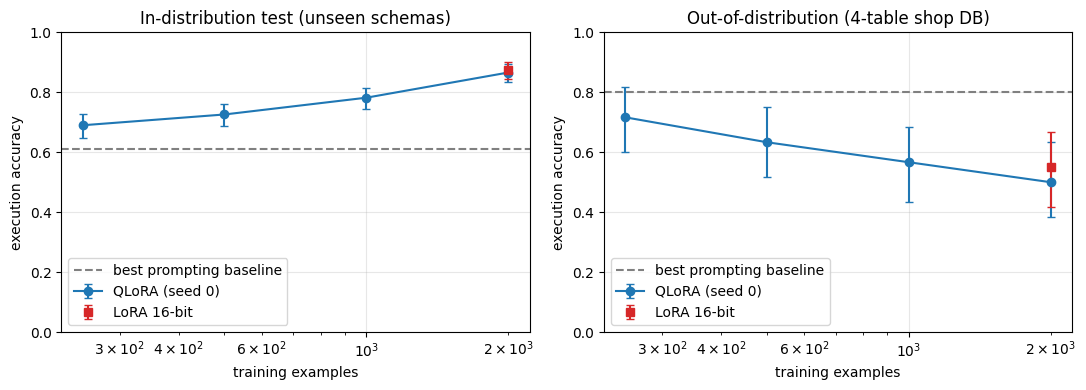

In [29]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, split, title in [(axes[0], "test", "In-distribution test (unseen schemas)"), (axes[1], "ood", "Out-of-distribution (4-table shop DB)")]:
    xs, ys, err = [], [], []
    for n in N_LIST:
        p = OUT / "preds" / f"{rname('qlora', n, 16, 'all', 0, 'test')}__{split}.csv"
        if not p.exists(): continue
        ok = pd.read_csv(p).exec_ok.values.astype(float); lo, hi = bootstrap_ci(ok)
        xs.append(n); ys.append(ok.mean()); err.append([ok.mean() - lo, hi - ok.mean()])
    ax.errorbar(xs, ys, yerr=np.array(err).T, marker="o", capsize=3, label="QLoRA (seed 0)")
    lp = OUT / "preds" / f"{NL}__{split}.csv"
    if lp.exists():
        ok = pd.read_csv(lp).exec_ok.values.astype(float); lo, hi = bootstrap_ci(ok)
        ax.errorbar([N_MAIN], [ok.mean()], yerr=[[ok.mean() - lo], [hi - ok.mean()]], fmt="s", color="C3", capsize=3, label="LoRA 16-bit")
    bp = OUT / "preds" / f"baseline_few_shot_plus__{split}.csv"
    if bp.exists():
        ax.axhline(pd.read_csv(bp).exec_ok.mean(), color="gray", ls="--", label="best prompting baseline")
    ax.set_xscale("log"); ax.set_xlabel("training examples"); ax.set_ylabel("execution accuracy")
    ax.set_title(title); ax.set_ylim(0, 1); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.savefig(OUT / "learning_curve.png", dpi=150); plt.show()

### 5e. Forgetting check
General knowledge (300 MMLU validation questions) before vs after fine-tuning. With n=300 the standard error is about 2.5 points, so only large drops are meaningful.

In [30]:
f = {"base model": base_mmlu}
for m in ["qlora", "lora"]:
    p = OUT / "results" / f"{rname(m, N_MAIN, 16, 'all', 0, 'test')}.json"
    if p.exists(): f[f"{m} (n={N_MAIN})"] = json.load(open(p)).get("mmlu")
print(pd.Series(f, name="MMLU subset accuracy").round(3).to_string())

base model        0.583
qlora (n=2000)    0.553
lora (n=2000)     0.593


### 5f. Error analysis: what did fine-tuning fix, and what is still broken?

,base (few-shot+),QLoRA,LoRA
category,,,
wrong aggregation,12.8,7.2,6.6
wrong columns/logic,14.4,3.2,2.6
wrong literal/value,4.4,2.6,3.2
join mismatch,0.8,0.2,0.2
ordering/limit,0.2,0.2,0.0
hallucinated column,6.4,0.0,0.0


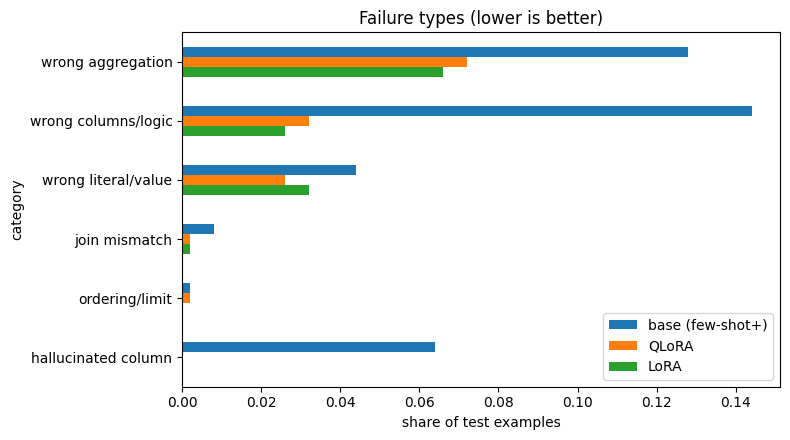


Ten QLoRA failures to read and write about in your report:

[wrong literal/value]
  Q   : What is the Russian word for wine glass that contains 4.16 fl. oz.?
  GOLD: SELECT russian FROM table_name_14 WHERE us_customary = "4.16 fl. oz."
  PRED: SELECT russian FROM table_name_14 WHERE us_customary = "wine glass" AND 4.16 = "fl. oz."

[wrong literal/value]
  Q   : Where is the venue with more than 245 runs?
  GOLD: SELECT venue FROM table_name_71 WHERE runs = "245"
  PRED: SELECT venue FROM table_name_71 WHERE runs > 245

[wrong aggregation]
  Q   : Name the silver for baseball
  GOLD: SELECT MIN(silver) FROM table_22360_3 WHERE discipline = "Baseball"
  PRED: SELECT AVG(silver) FROM table_22360_3 WHERE discipline = "Baseball"

[wrong columns/logic]
  Q   : Name the regular season for usisl d-3 pro league did not qualify
  GOLD: SELECT regular_season FROM table_2361911_2 WHERE league = "USISL D-3 Pro league" AND playoffs = "Did not qualify"
  PRED: SELECT regular_season FROM table_236191

In [31]:
cats = pd.DataFrame({
    "base (few-shot+)": load_preds("baseline_few_shot_plus").category.value_counts(normalize=True),
    "QLoRA":            load_preds(NQ).category.value_counts(normalize=True),
    "LoRA":             load_preds(NL).category.value_counts(normalize=True)}).fillna(0)
cats = cats.drop(index="correct").sort_values("QLoRA", ascending=False)
display((cats * 100).round(1))
cats.plot.barh(figsize=(8, 4.5)); plt.xlabel("share of test examples"); plt.title("Failure types (lower is better)")
plt.gca().invert_yaxis(); plt.tight_layout(); plt.savefig(OUT / "error_categories.png", dpi=150); plt.show()

ft = load_preds(NQ)
print("\nTen QLoRA failures to read and write about in your report:\n")
for _, r in ft[~ft.exec_ok].sample(10, random_state=0).iterrows():
    print(f"[{r.category}]\n  Q   : {r.question}\n  GOLD: {r.answer}\n  PRED: {r.pred}\n")

ood_ft = load_preds(NQ, "ood")
print("OOD failure types (QLoRA):"); print(ood_ft.category.value_counts().to_string())